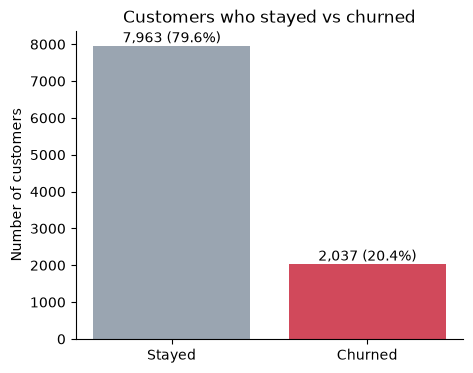

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/processed/bank_churn_clean.csv")

counts = df["Exited"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(["Stayed", "Churned"], counts.values, color=["#9aa5b1", "#d1495b"])
ax.bar_label(bars, labels=[f"{c:,} ({c / len(df):.1%})" for c in counts.values])
ax.set_title("Customers who stayed vs churned")
ax.set_ylabel("Number of customers")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

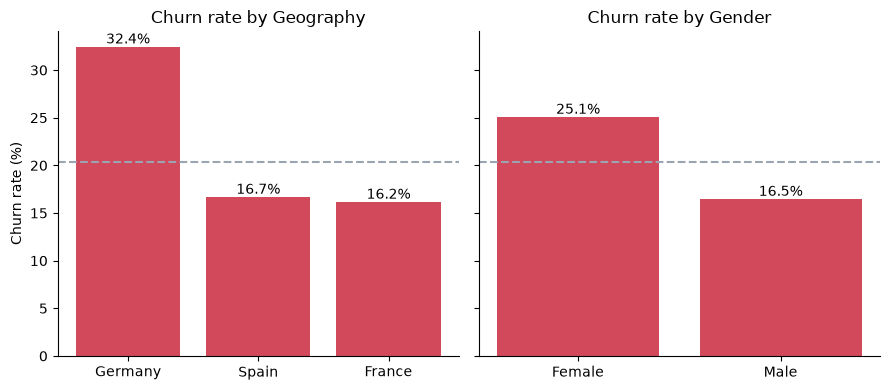

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)

for ax, col in zip(axes, ["Geography", "Gender"]):
    rate = df.groupby(col)["Exited"].mean().sort_values(ascending=False) * 100
    bars = ax.bar(rate.index, rate.values, color="#d1495b")
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in rate.values])
    ax.axhline(df["Exited"].mean() * 100, color="#9aa5b1", linestyle="--")
    ax.set_title(f"Churn rate by {col}")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Churn rate (%)")
plt.tight_layout()
plt.show()

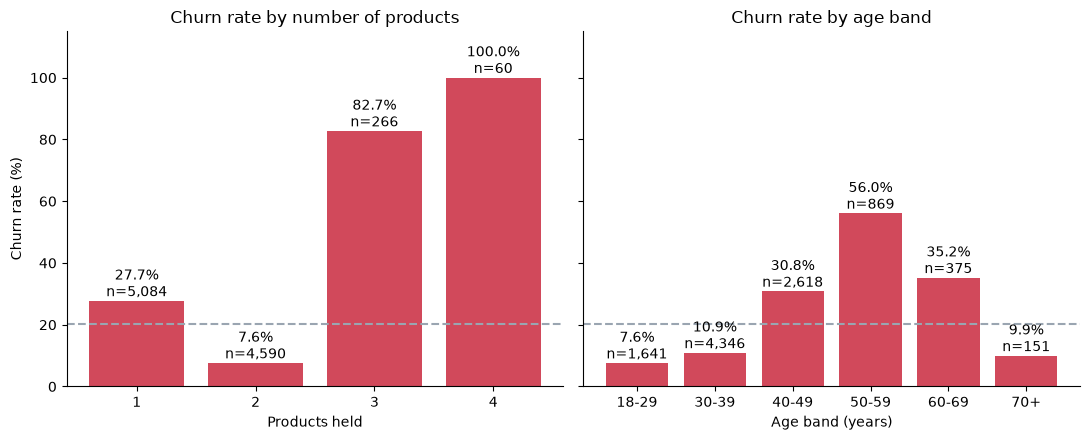

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
overall = df["Exited"].mean() * 100

rate_p = df.groupby("NumOfProducts")["Exited"].mean() * 100
n_p = df["NumOfProducts"].value_counts().sort_index()
bars = axes[0].bar(rate_p.index.astype(str), rate_p.values, color="#d1495b")
axes[0].bar_label(bars, labels=[f"{r:.1f}%\nn={n:,}" for r, n in zip(rate_p.values, n_p.values)])
axes[0].set_title("Churn rate by number of products")
axes[0].set_xlabel("Products held")

bands = pd.cut(df["Age"], bins=[17, 29, 39, 49, 59, 69, 92],
               labels=["18-29", "30-39", "40-49", "50-59", "60-69", "70+"])
rate_a = df.groupby(bands, observed=True)["Exited"].mean() * 100
n_a = bands.value_counts().sort_index()
bars = axes[1].bar(rate_a.index.astype(str), rate_a.values, color="#d1495b")
axes[1].bar_label(bars, labels=[f"{r:.1f}%\nn={n:,}" for r, n in zip(rate_a.values, n_a.values)])
axes[1].set_title("Churn rate by age band")
axes[1].set_xlabel("Age band (years)")

for ax in axes:
    ax.axhline(overall, color="#9aa5b1", linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 115)
plt.tight_layout()
plt.show()

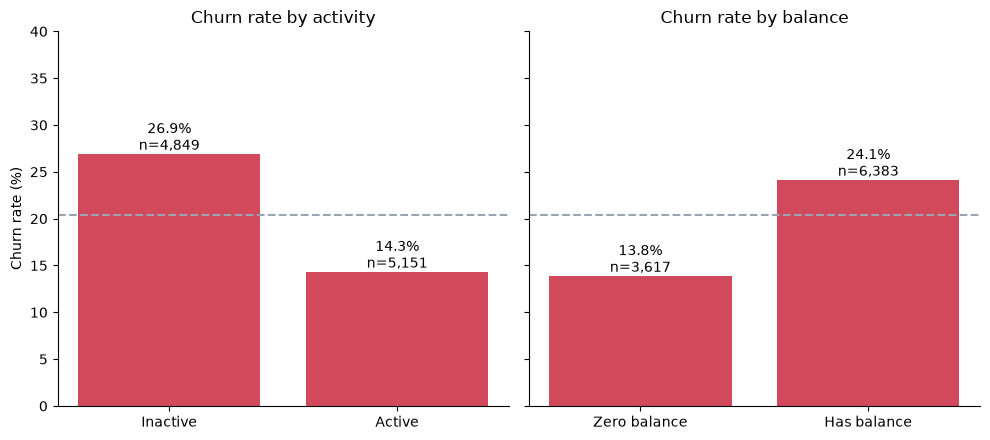

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
overall = df["Exited"].mean() * 100

rate_act = df.groupby("IsActiveMember")["Exited"].mean() * 100
n_act = df["IsActiveMember"].value_counts().sort_index()
bars = axes[0].bar(["Inactive", "Active"], rate_act.values, color="#d1495b")
axes[0].bar_label(bars, labels=[f"{r:.1f}%\nn={n:,}" for r, n in zip(rate_act.values, n_act.values)])
axes[0].set_title("Churn rate by activity")

order = ["Zero balance", "Has balance"]
bal_group = df["Balance"].eq(0).map({True: "Zero balance", False: "Has balance"})
rate_bal = df.groupby(bal_group)["Exited"].mean().reindex(order) * 100
n_bal = bal_group.value_counts().reindex(order)
bars = axes[1].bar(order, rate_bal.values, color="#d1495b")
axes[1].bar_label(bars, labels=[f"{r:.1f}%\nn={n:,}" for r, n in zip(rate_bal.values, n_bal.values)])
axes[1].set_title("Churn rate by balance")

for ax in axes:
    ax.axhline(overall, color="#9aa5b1", linestyle="--")
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 40)
plt.tight_layout()
plt.show()